In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression

In [10]:
df = pd.read_csv("iris - iris.csv")
df = df.drop_duplicates()
df.isna().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [11]:
df = df.drop_duplicates()
df.isna().sum()

sepal.length    0
sepal.width     0
petal.length    0
petal.width     0
variety         0
dtype: int64

In [12]:
le = LabelEncoder()

df["variety"] = le.fit_transform(df["variety"])

In [13]:
X = df.drop('variety',axis=1)
y = df['variety']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [14]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)

print("KNN model trained successfully.")

KNN model trained successfully.


In [15]:
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Training Precision:", precision_score(y_train, y_train_pred, average="macro", zero_division=0))
print("Training Recall:", recall_score(y_train, y_train_pred, average="macro", zero_division=0))
print("Training F1-Score:", f1_score(y_train, y_train_pred, average="macro", zero_division=0))

print("\nTraining Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred))

Training Accuracy: 0.957983193277311
Training Precision: 0.9576923076923077
Training Recall: 0.9580658964484381
Training F1-Score: 0.9577788466677356

Training Confusion Matrix:
[[40  0  0]
 [ 0 38  3]
 [ 0  2 36]]


In [16]:
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))
print("Testing Precision:", precision_score(y_test, y_test_pred, average="macro", zero_division=0))
print("Testing Recall:", recall_score(y_test, y_test_pred, average="macro", zero_division=0))
print("Testing F1-Score:", f1_score(y_test, y_test_pred, average="macro", zero_division=0))

print("\nTesting Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

Testing Accuracy: 1.0
Testing Precision: 1.0
Testing Recall: 1.0
Testing F1-Score: 1.0

Testing Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


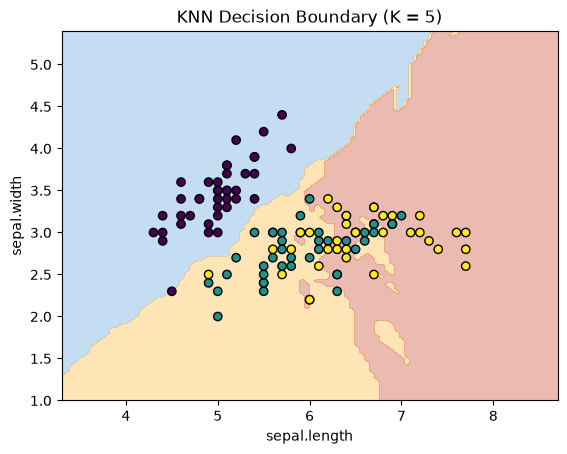

In [17]:
X_2d = X_train.iloc[:, :2]

knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(X_2d, y_train)

DecisionBoundaryDisplay.from_estimator(
    knn_2d,
    X_2d,
    response_method="predict",
    xlabel=X_2d.columns[0],
    ylabel=X_2d.columns[1],
    alpha=0.3
)

plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=pd.factorize(y_train)[0],
    edgecolor="black"
)

plt.title("KNN Decision Boundary (K = 5)")
plt.show()

In [18]:
lr = LogisticRegression()
lr.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:
y_pred_lr = lr.predict(X_test)
y_train_pred_lr = lr.predict(X_train)

In [20]:
print("\nLogistic Regression")
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred_lr))

print("Testing Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


Logistic Regression
Training Confusion Matrix:
[[40  0  0]
 [ 0 38  3]
 [ 0  1 37]]
Testing Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [21]:
print("The scores for training data are:")
print(accuracy_score(y_train, y_train_pred_lr))
print(precision_score(y_train, y_train_pred_lr, average='macro'))
print(recall_score(y_train, y_train_pred_lr, average='macro'))
print(f1_score(y_train, y_train_pred_lr, average='macro'))

The scores for training data are:
0.9663865546218487
0.9664529914529915
0.9668378262729996
0.9662393162393162


In [21]:
print("\nLogistic Regression")
print("Training Confusion Matrix:")
print(confusion_matrix(y_train, y_train_pred_lr))

print("Testing Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


Logistic Regression
Training Confusion Matrix:
[[40  0  0]
 [ 0 38  3]
 [ 0  1 37]]
Testing Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [22]:
print("The scores for testing data are:")
print(accuracy_score(y_test, y_pred_lr))
print(precision_score(y_test, y_pred_lr, average='macro'))
print(recall_score(y_test, y_pred_lr, average='macro'))
print(f1_score(y_test, y_pred_lr, average='macro'))

The scores for testing data are:
1.0
1.0
1.0
1.0


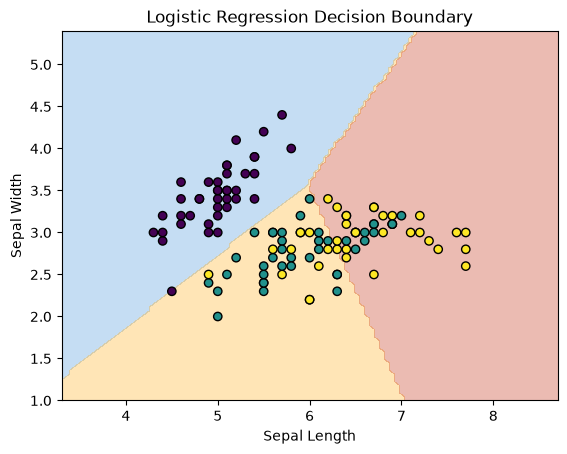

In [23]:
lr_2d = LogisticRegression().fit(X_2d,y_train)

DecisionBoundaryDisplay.from_estimator(
    lr_2d,
    X_2d,
    response_method="predict",
    xlabel="Sepal Length",
    ylabel="Sepal Width",
    alpha=0.3
)

plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=pd.factorize(y_train)[0],
    edgecolor="black"
)

plt.title("Logistic Regression Decision Boundary")
plt.show()

In [24]:
def flower():
    sepal_length = float(input("Enter sepal length: "))
    sepal_width = float(input("Enter sepal width: "))
    petal_length = float(input("Enter petal length: "))
    petal_width = float(input("Enter petal width: "))

    predicted = lr.predict([[sepal_length, sepal_width, petal_length, petal_width]])

    plt.scatter(df[y == 0]["petal.length"], df[y == 0]["petal.width"],
                color='red', label='Setosa')

    plt.scatter(df[y == 1]["petal.length"], df[y == 1]["petal.width"],
                color='green', label='Versicolor')

    plt.scatter(df[y == 2]["petal.length"], df[y == 2]["petal.width"],
                color='blue', label='Virginica')

    if predicted[0] == 0:
        print("The species is: Setosa")
        plt.scatter(petal_length, petal_width, color='red',
                    marker='+', s=200, linewidths=3, label='Predicted Flower')

    elif predicted[0] == 1:
        print("The species is: Versicolor")
        plt.scatter(petal_length, petal_width, color='green',
                    marker='+', s=200, linewidths=3, label='Predicted Flower')

    else:
        print("The species is: Virginica")
        plt.scatter(petal_length, petal_width, color='blue',
                    marker='+', s=200, linewidths=3, label='Predicted Flower')

    plt.xlabel("Petal Length")
    plt.ylabel("Petal Width")
    plt.title("Iris Dataset with Predicted Flower")
    plt.legend()
    plt.show()

Enter sepal length:  6
Enter sepal width:  3
Enter petal length:  3
Enter petal width:  1.5


C:\Users\vishw\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


The species is: Versicolor


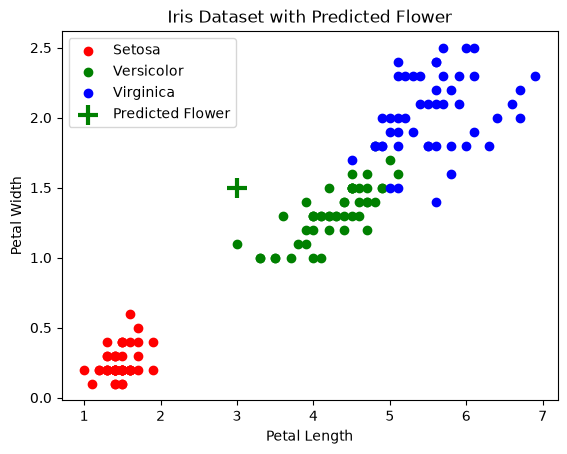

In [25]:
flower()